In [ ]:
from google.colab import files
uploaded = files.upload()

In [19]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

img = cv2.imread("chessboard  köşe tespiti  (1).png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray = gray.astype(np.float32)

Ix = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
Iy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

Ixx = Ix * Ix
Iyy = Iy * Iy
Ixy = Ix * Iy

window_size = 5
Sxx = cv2.boxFilter(Ixx, ddepth=-1, ksize=(window_size, window_size))
Syy = cv2.boxFilter(Iyy, ddepth=-1, ksize=(window_size, window_size))
Sxy = cv2.boxFilter(Ixy, ddepth=-1, ksize=(window_size, window_size))

trace = Sxx + Syy
det_term = np.sqrt(((Sxx - Syy) / 2) ** 2 + Sxy ** 2)

lambda1 = trace / 2 + det_term
harris_response = trace / 2 - det_term

In [20]:
alpha = 1/25

det_H = Sxx * Syy - Sxy**2
trace_H = Sxx + Syy

harris_response = det_H - alpha * (trace_H ** 2)

print(harris_response.min(), harris_response.max())

-6927565824.0 77589349870.64345


In [21]:
threshold_ratio_harris = 0.01
threshold_harris = threshold_ratio_harris * harris_response.max()

corners_mask_harris = harris_response > threshold_harris

local_max_harris = maximum_filter(harris_response, size=7)
is_local_max_harris = (harris_response == local_max_harris)

corners_nms_harris = corners_mask_harris & is_local_max_harris

print(corners_nms_harris.sum())

90


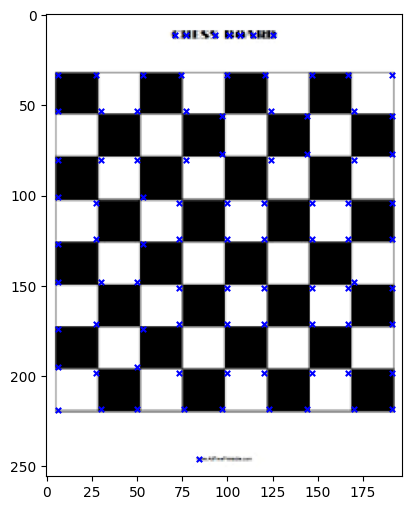

In [22]:
img_color = cv2.imread("chessboard  köşe tespiti  (2).png")
ys_h, xs_h = np.where(corners_nms_harris)
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.scatter(xs_h, ys_h, s=15, c='blue', marker='x')
plt.show()

In [23]:
for alpha_test in [0.02, 0.03, 0.04]:
    hr = det_H - alpha_test * (trace_H ** 2)
    thr = 0.01 * hr.max()
    mask = hr > thr
    lm = maximum_filter(hr, size=7)
    is_lm = (hr == lm)
    nms = mask & is_lm
    print(f"alpha={alpha_test}: {nms.sum()} köşe bulundu")
    #alpha arttıkça bulunan köşe sayısı azalıyor.çünlü alpha nın Tr(H)² ye uyguladığı ceza arttıkça algoritma daha seçici hale geliyor.

alpha=0.02: 92 köşe bulundu
alpha=0.03: 91 köşe bulundu
alpha=0.04: 90 köşe bulundu
